# Simulations

Stationary, heterogeneous, and change-point time series; nine conformal prediction methods with target coverage 90%.


In [1]:
# Locate the project root.
from pathlib import Path
import sys
_PROJECT_CANDIDATES = (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
PROJECT_ROOT = next((p for p in _PROJECT_CANDIDATES if (p / "cp_methods.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project directory.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "data"

import contextlib
from functools import partial
import io
import os
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantile_forest
import sklearn
from IPython.display import display, Image
from sklearn.linear_model import LinearRegression

import cp_methods as cpm

T = 1500
BURN_IN = 500
R = 200
ALPHA = 0.1
N_REPS = 100
SEED = 42
SCENARIOS = ('A', 'B', 'C')
SPCI_W_LAG = 8
SPCI_T_TRAIN = 200
SPCI_REFIT_EVERY = 100
N_BINS = 10
ROLLING_WINDOW = 100

# Run SPCI last.
METHOD_RUNNERS = {
    'cp': cpm.eval_cp,
    'cop': cpm.eval_cop,
    'lqt': cpm.eval_lqt,
    'lcp': cpm.eval_lcp,
    'aci': cpm.eval_aci,
    'dtaci': cpm.eval_dtaci,
    'olcp': cpm.eval_olcp,
    'olcph': partial(cpm.eval_olcp_adahedge),
    'spci': partial(cpm.eval_spci, w_lag=SPCI_W_LAG,
                    T_train=SPCI_T_TRAIN, refit_every=SPCI_REFIT_EVERY),
}
METHOD_ORDER = ['cp', 'lcp', 'aci', 'dtaci', 'cop', 'lqt', 'spci', 'olcp', 'olcph']
LABELS = {'cp': 'CP', 'lcp': 'LCP', 'aci': 'ACI', 'dtaci': 'DtACI',
          'cop': 'COP', 'lqt': 'LQT', 'spci': 'SPCI',
          'olcp': 'OLCP', 'olcph': 'OLCP-Hedge'}

display(pd.Series({
    'Python': platform.python_version(), 'NumPy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'quantile-forest': quantile_forest.__version__, 'joblib CPUs': joblib.cpu_count(),
    'LOKY_MAX_CPU_COUNT': os.environ.get('LOKY_MAX_CPU_COUNT', 'not set'),
    'OPENBLAS_NUM_THREADS': os.environ.get('OPENBLAS_NUM_THREADS', 'not set'),
    'OMP_NUM_THREADS': os.environ.get('OMP_NUM_THREADS', 'not set'),
}, name='Execution environment'))

Python                  3.11.14
NumPy                    1.26.4
pandas                    2.3.3
scikit-learn              1.7.2
quantile-forest           1.4.1
joblib CPUs                   1
LOKY_MAX_CPU_COUNT            1
OPENBLAS_NUM_THREADS          1
OMP_NUM_THREADS               1
Name: Execution environment, dtype: object

## Data-generating processes

With $X_t=Y_{t-1}$ and $\varepsilon_t\sim\mathcal N(0,1)$:

- **A (stationary):** $Y_t=0.5Y_{t-1}+\varepsilon_t$.
- **B (heterogeneous):** $Y_t=0.5Y_{t-1}+\min\{e^{0.25Y_{t-1}},10\}\varepsilon_t$.
- **C (change point):** $Y_t=\phi_tY_{t-1}+\varepsilon_t$, where $\phi_t=0.8$ before the midpoint and $-0.8$ after.


In [2]:
def generate_data(scenario, T):
    """Generate one simulation sequence."""
    y = np.zeros(T + 1)
    y[0] = np.random.randn()
    if scenario == 'A':
        for t in range(1, T + 1):
            y[t] = 0.5 * y[t-1] + np.random.randn()
    elif scenario == 'B':
        for t in range(1, T + 1):
            sigma_t = np.min([np.exp(0.5 * y[t-1])**0.5, 10])
            y[t] = 0.5 * y[t-1] + sigma_t * np.random.randn()
    elif scenario == 'C':
        for t in range(1, T + 1):
            phi = 0.8 if t <= T // 2 else -0.8
            y[t] = phi * y[t-1] + np.random.randn()
    else:
        raise ValueError(f'Unknown scenario: {scenario}')
    return y[:-1].reshape(-1, 1), y[1:], y


def make_simulation_data(scenario):
    X, y, _ = generate_data(scenario, T)
    model = LinearRegression().fit(X[:BURN_IN], y[:BURN_IN])
    pred = np.asarray(model.predict(X), dtype=float).ravel()
    score = np.abs(y - pred)
    warmup = max(R, SPCI_W_LAG, SPCI_T_TRAIN)
    test_start = max(0, BURN_IN - warmup)
    data = [{
        'series_id': 0, 'ts': pd.RangeIndex(T),
        'y': y, 'pred': pred, 'score': score, 'X': X,
        'is_test': np.arange(T) >= test_start, 'const_test': False,
    }]
    return data, X[BURN_IN:, 0]

## Monte Carlo evaluation

One hundred repetitions of length $T=1{,}500$. Fit the base predictor using the first 500 observations; rolling calibration window $R=200$; evaluate the final 1,000 observations.


In [3]:
np.random.seed(SEED)
metric_rows, boundary_rows = [], []
covariates_B = []
traces = {s: {m: {'covered': [], 'width': []} for m in METHOD_ORDER} for s in ('B', 'C')}

for rep in range(N_REPS):
    for scenario in SCENARIOS:
        data, x_test = make_simulation_data(scenario)
        if scenario == 'B':
            covariates_B.append(x_test.copy())
        for method, runner in METHOD_RUNNERS.items():
            with contextlib.redirect_stdout(io.StringIO()):
                result, seconds = runner(
                    data, alpha=ALPHA, R=R,
                    exclude_const_test=False, show_pbar=False,
                )
            result = result.loc[result['t'] >= BURN_IN].reset_index(drop=True)
            assert len(result) == T - BURN_IN
            np.testing.assert_array_equal(result['t'], np.arange(BURN_IN, T))
            covered = result['covered'].to_numpy(dtype=bool)
            width = result['width'].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
            metric_rows.append({
                'Repetition': rep, 'Scenario': scenario, 'Method': method,
                'Coverage': covered.mean(), 'Size': np.nanmean(width),
                'Seconds': float(seconds),
            })
            if scenario in traces:
                traces[scenario][method]['covered'].append(covered)
                traces[scenario][method]['width'].append(width)
            if method in ('aci', 'olcp'):
                boundary_rows.append({
                    'Scenario': scenario, 'Method': method, 'Rounds': len(result),
                    'L_sum': (result['L_t'] / result['gamma']).sum(),
                    'U_sum': (result['U_t'] / result['gamma']).sum(),
                    'L_hits': result['L_hit'].sum(), 'U_hits': result['U_hit'].sum(),
                })
    if (rep + 1) % 10 == 0:
        print(f'Completed {rep + 1}/{N_REPS} repetitions for all nine methods.')

replicate_metrics = pd.DataFrame(metric_rows)
summary = replicate_metrics.groupby(['Scenario', 'Method'], as_index=False).agg(
    Coverage_mean=('Coverage', 'mean'), Coverage_SD=('Coverage', 'std'),
    Size_mean=('Size', 'mean'), Size_SD=('Size', 'std'),
    Seconds_mean=('Seconds', 'mean'), Seconds_SD=('Seconds', 'std'),
    Repetitions=('Repetition', 'nunique'),
)
assert len(summary) == len(SCENARIOS) * len(METHOD_RUNNERS)
assert summary['Repetitions'].eq(N_REPS).all()
for scenario in traces:
    for method in METHOD_ORDER:
        for metric in ('covered', 'width'):
            traces[scenario][method][metric] = np.stack(traces[scenario][method][metric])
covariates_B = np.stack(covariates_B)

Completed 10/100 repetitions for all nine methods.
Completed 20/100 repetitions for all nine methods.
Completed 30/100 repetitions for all nine methods.
Completed 40/100 repetitions for all nine methods.
Completed 50/100 repetitions for all nine methods.
Completed 60/100 repetitions for all nine methods.
Completed 70/100 repetitions for all nine methods.
Completed 80/100 repetitions for all nine methods.
Completed 90/100 repetitions for all nine methods.
Completed 100/100 repetitions for all nine methods.


## Coverage and interval width

Mean and standard deviation across 100 repetitions.


In [4]:
lookup = summary.set_index(['Scenario', 'Method'])
performance_rows = []
for method in METHOD_ORDER:
    row = {'Method': LABELS[method]}
    for scenario in SCENARIOS:
        values = lookup.loc[(scenario, method)]
        row[f'{scenario}: Coverage'] = f"{values.Coverage_mean:.3f} ({values.Coverage_SD:.3f})"
        row[f'{scenario}: Size'] = f"{values.Size_mean:.3f} ({values.Size_SD:.3f})"
    performance_rows.append(row)
performance_table = pd.DataFrame(performance_rows).set_index('Method')
display(performance_table)

,A: Coverage,A: Size,B: Coverage,B: Size,C: Coverage,C: Size
Method,,,,,,
CP,0.900 (0.004),3.329 (0.079),0.900 (0.005),3.613 (0.159),0.869 (0.008),7.295 (0.474)
LCP,0.893 (0.005),3.300 (0.078),0.894 (0.005),3.434 (0.124),0.880 (0.007),6.036 (0.293)
ACI,0.900 (0.003),3.357 (0.096),0.900 (0.003),3.733 (0.218),0.899 (0.004),7.841 (0.509)
DtACI,0.900 (0.003),3.347 (0.094),0.900 (0.004),3.691 (0.191),0.897 (0.004),7.757 (0.495)
COP,0.900 (0.001),3.406 (0.092),0.898 (0.002),3.850 (0.211),0.892 (0.002),7.558 (0.446)
LQT,0.896 (0.002),3.353 (0.086),0.898 (0.002),3.806 (0.205),0.892 (0.002),6.481 (0.303)
SPCI,0.814 (0.010),2.874 (0.070),0.819 (0.010),3.046 (0.112),0.771 (0.014),3.378 (0.095)
OLCP,0.901 (0.002),3.401 (0.095),0.901 (0.002),3.550 (0.139),0.900 (0.003),6.301 (0.283)
OLCP-Hedge,0.900 (0.003),3.403 (0.094),0.900 (0.004),3.550 (0.139),0.899 (0.004),6.312 (0.285)


## Running time

Wall-clock runtime of conformal calibration, excluding simulation, base-model fitting, and plotting.


In [5]:
runtime_table = summary.pivot(index='Method', columns='Scenario', values='Seconds_mean')
runtime_table = runtime_table.reindex(METHOD_ORDER).rename(index=LABELS)
display(runtime_table.round(3))

Scenario,A,B,C
Method,,,
CP,0.007,0.007,0.007
LCP,0.030,0.030,0.030
ACI,0.010,0.009,0.009
DtACI,0.019,0.018,0.018
COP,0.007,0.007,0.008
LQT,0.005,0.005,0.006
SPCI,1.614,1.623,1.602
OLCP,0.033,0.032,0.032
OLCP-Hedge,0.097,0.097,0.096


## Projection diagnostics

Normalized boundary corrections and activation frequencies for ACI and OLCP.


In [6]:
boundary_totals = pd.DataFrame(boundary_rows).groupby(['Scenario', 'Method']).sum()
boundary_diagnostics = pd.DataFrame({
    'L_bar': boundary_totals['L_sum'] / boundary_totals['Rounds'],
    'U_bar': boundary_totals['U_sum'] / boundary_totals['Rounds'],
    'f_L': boundary_totals['L_hits'] / boundary_totals['Rounds'],
    'f_U': boundary_totals['U_hits'] / boundary_totals['Rounds'],
}).reset_index()
boundary_diagnostics['Method'] = boundary_diagnostics['Method'].map(LABELS)
display(boundary_diagnostics.style.format({c: '{:.6f}' for c in ['L_bar', 'U_bar', 'f_L', 'f_U']}))

,Scenario,Method,L_bar,U_bar,f_L,f_U
0,A,ACI,0.000000,0.000000,0.000000,0.000000
1,A,OLCP,0.000003,0.000000,0.000020,0.000000
2,B,ACI,0.000031,0.000000,0.000100,0.000000
3,B,OLCP,0.000003,0.000000,0.000010,0.000000
4,C,ACI,0.001470,0.000000,0.002780,0.000000
5,C,OLCP,0.001682,0.000000,0.003120,0.000000


## Scenario B: conditional behavior

Coverage and interval width across deciles of the lagged response; bands indicate one standard deviation across repetitions.


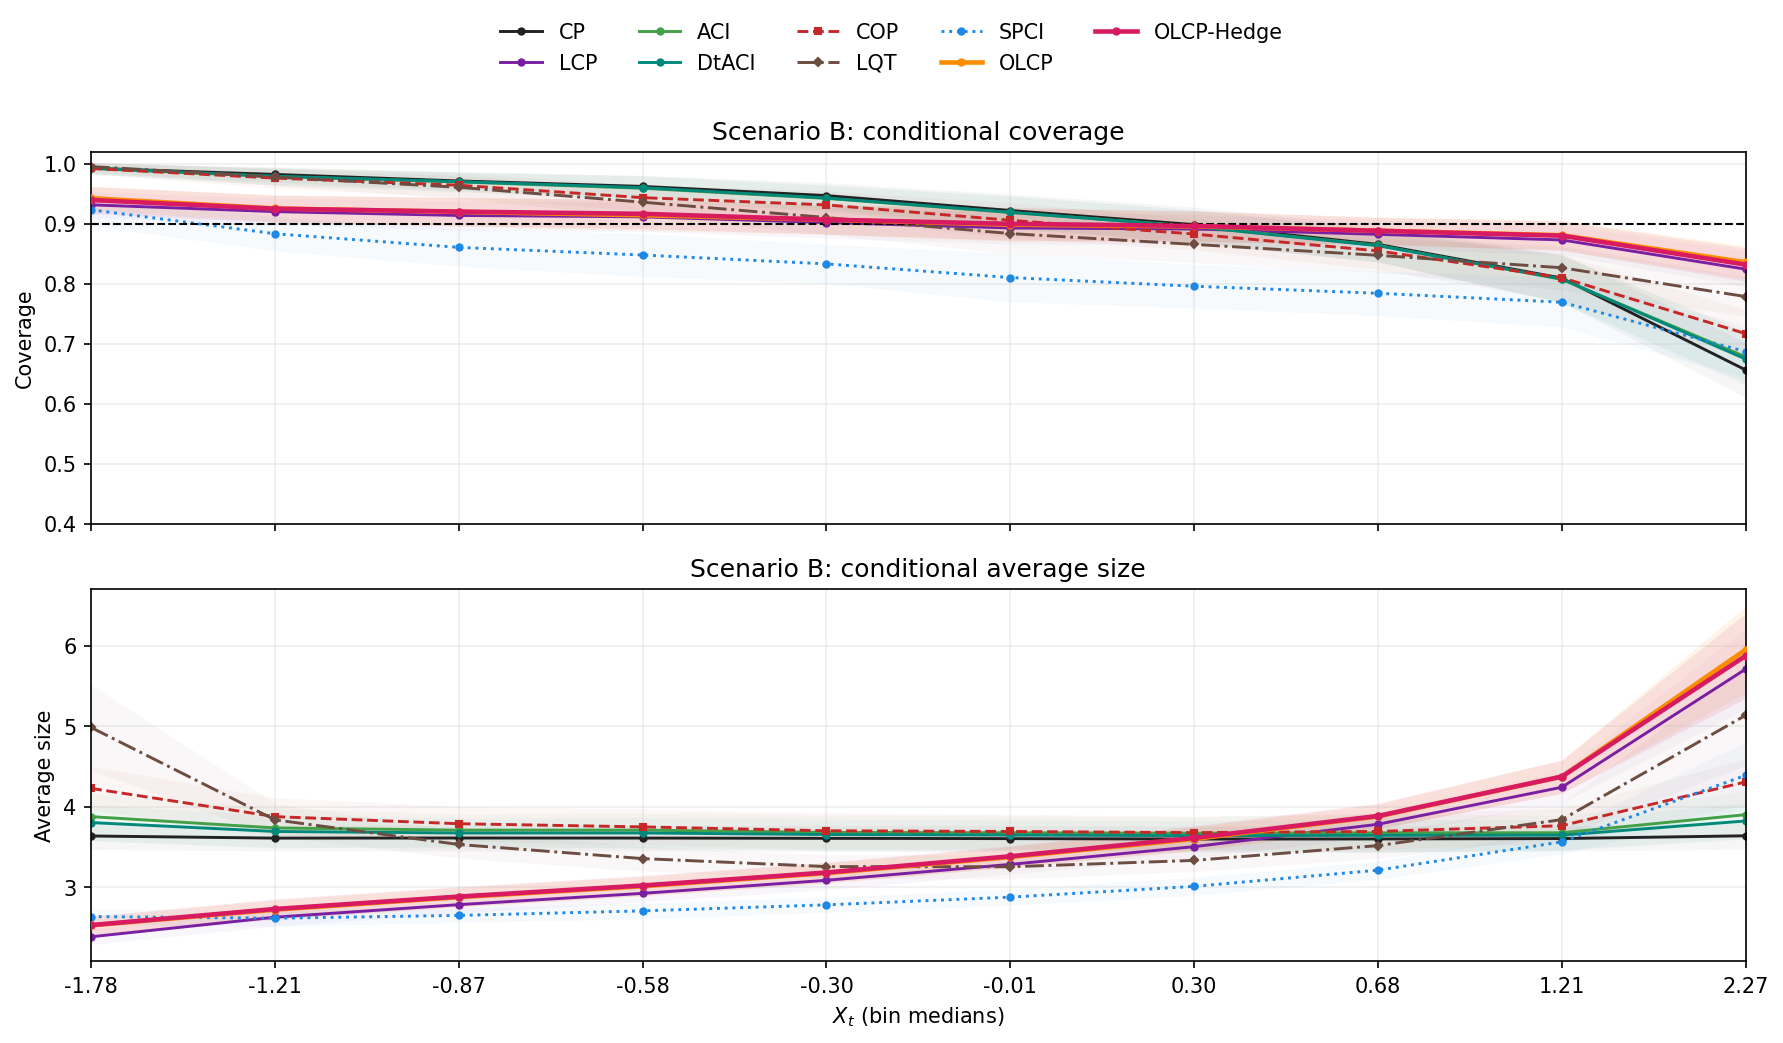

In [7]:
COLORS = dict(zip(METHOD_ORDER, [
    '#222222', '#7B1FA2', '#43A047', '#00897B', '#C62828',
    '#6D4C41', '#1E88E5', '#FB8C00', '#D81B60',
]))
LINESTYLES = {'cop': '--', 'lqt': '-.', 'spci': ':'}
MARKERS = {'cop': 's', 'lqt': 'D'}


def plot_diagnostics(x, curves, xlabel, titles, ticklabels=None, change_time=None):
    """Plot per-repetition metric arrays with mean ± one SD."""
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    handles = []
    for method in METHOD_ORDER:
        emphasis = method in ('olcp', 'olcph')
        for ax, metric in zip(axes, ('covered', 'width')):
            values = curves[method][metric]
            mean = np.nanmean(values, axis=0)
            sd = np.nanstd(values, axis=0)
            line, = ax.plot(
                x, mean, color=COLORS[method], label=LABELS[method],
                linestyle=LINESTYLES.get(method, '-'),
                linewidth=2.2 if emphasis else 1.4,
                marker=MARKERS.get(method, 'o') if ticklabels is not None else None,
                markersize=3, zorder=4 if emphasis else 2,
            )
            ax.fill_between(x, mean - sd, mean + sd, color=COLORS[method],
                            alpha=0.09 if emphasis else 0.04, linewidth=0)
            if metric == 'covered':
                handles.append(line)
    axes[0].axhline(1 - ALPHA, color='black', linestyle='--', linewidth=1)
    axes[0].set_ylim(0.4, 1.02)
    axes[0].set_ylabel('Coverage')
    axes[1].set_ylabel('Average size')
    axes[1].set_xlabel(xlabel)
    for ax, title in zip(axes, titles):
        ax.set_title(title)
        ax.grid(alpha=0.2)
        if change_time is not None:
            ax.axvline(change_time, color='black', linestyle='--', linewidth=1)
    if ticklabels is not None:
        axes[1].set_xticks(x, ticklabels)
    axes[1].set_xlim(x[0], x[-1])
    fig.legend(handles, [LABELS[m] for m in METHOD_ORDER], loc='upper center',
               bbox_to_anchor=(0.5, 1.0), ncol=5, frameon=False, fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.91))
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


edges = np.unique(np.quantile(covariates_B, np.linspace(0, 1, N_BINS + 1)))
assert len(edges) == N_BINS + 1
conditional = {m: {'covered': [], 'width': []} for m in METHOD_ORDER}
medians = []
for rep, x in enumerate(covariates_B):
    bins = pd.cut(x, bins=edges, include_lowest=True, labels=False)
    medians.append(pd.Series(x).groupby(bins).median().reindex(range(N_BINS)).to_numpy())
    for method in METHOD_ORDER:
        for metric in ('covered', 'width'):
            values = traces['B'][method][metric][rep]
            means = pd.Series(values).groupby(bins).mean().reindex(range(N_BINS)).to_numpy()
            conditional[method][metric].append(means)
for method in METHOD_ORDER:
    for metric in ('covered', 'width'):
        conditional[method][metric] = np.stack(conditional[method][metric])

plot_diagnostics(
    np.arange(N_BINS), conditional, '$X_{t}$ (bin medians)',
    ('Scenario B: conditional coverage', 'Scenario B: conditional average size'),
    ticklabels=[f'{x:.2f}' for x in np.nanmean(medians, axis=0)],
)

## Scenario C: change-point behavior

Rolling coverage and width (window 100), with the change point at $t=750$.


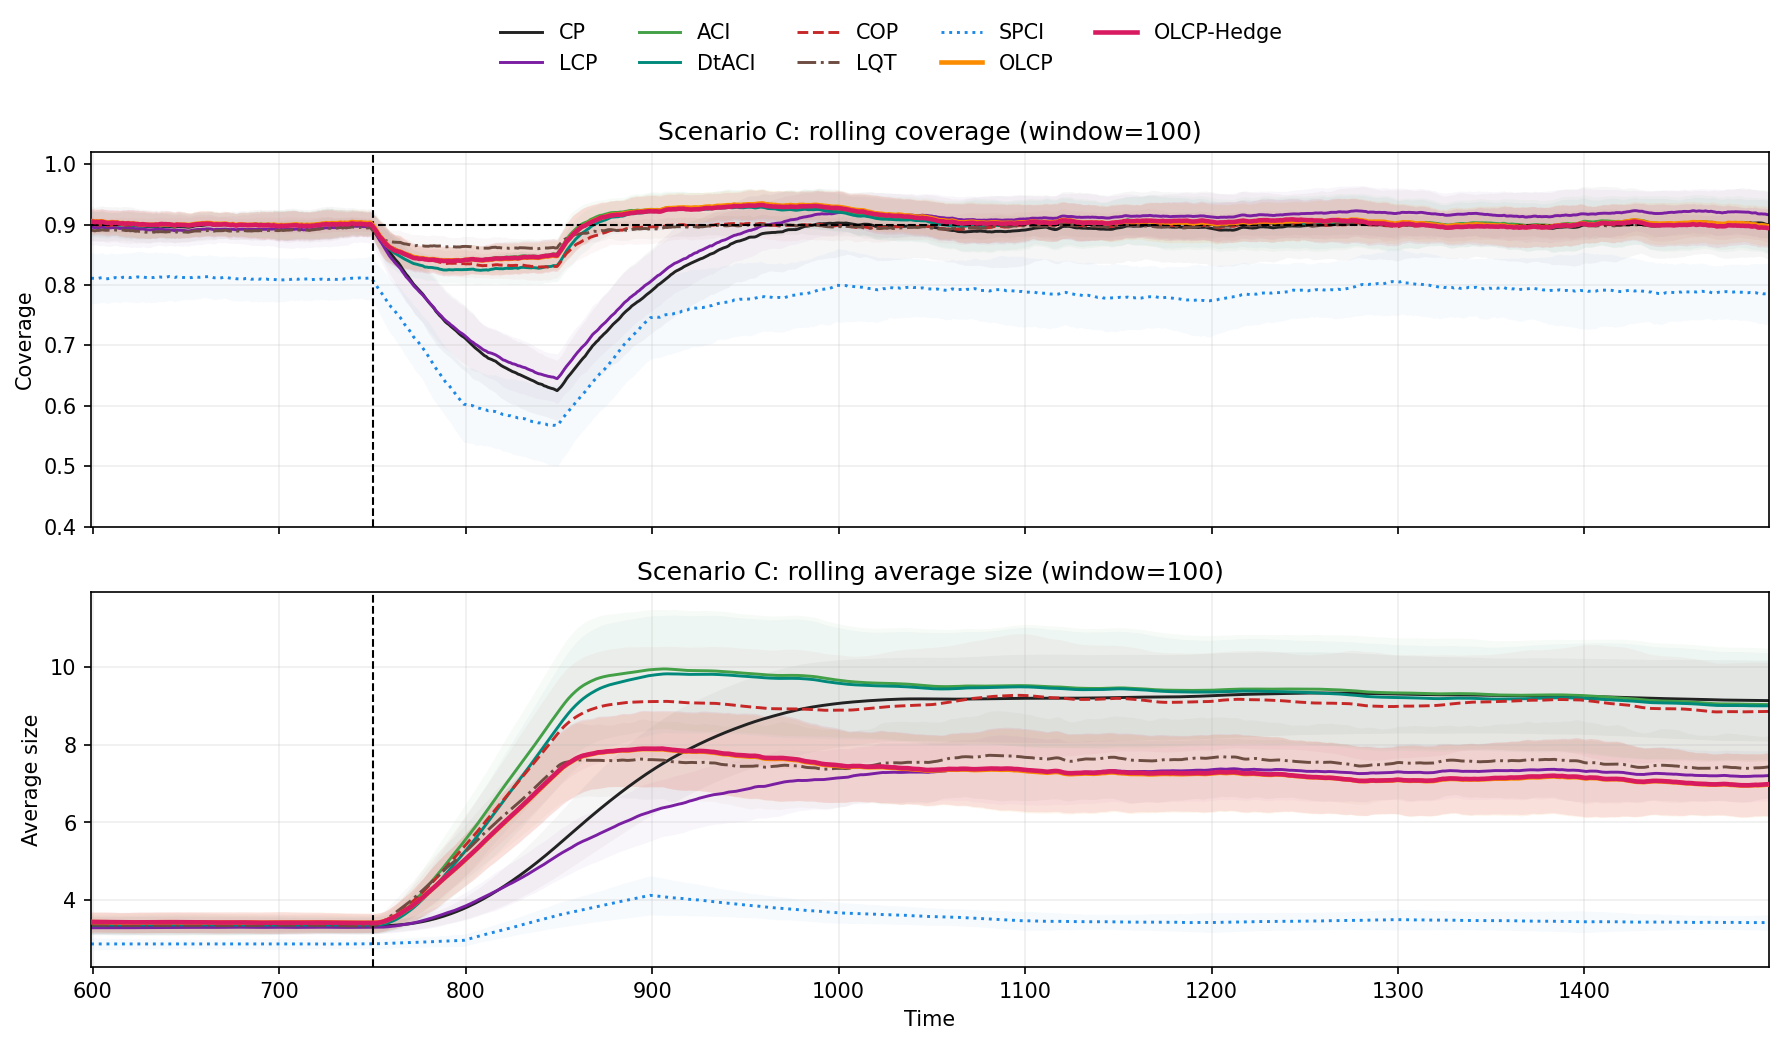

In [8]:
rolling = {m: {} for m in METHOD_ORDER}
for method in METHOD_ORDER:
    for metric in ('covered', 'width'):
        values = traces['C'][method][metric].astype(float)
        smoothed = pd.DataFrame(values.T).rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
        rolling[method][metric] = smoothed.to_numpy().T[:, ROLLING_WINDOW - 1:]

time = np.arange(BURN_IN, T)[ROLLING_WINDOW - 1:]
plot_diagnostics(
    time, rolling, 'Time',
    (f'Scenario C: rolling coverage (window={ROLLING_WINDOW})',
     f'Scenario C: rolling average size (window={ROLLING_WINDOW})'),
    change_time=T // 2,
)